0.21150306788374618
0.6087656426393592
white_castled_10
0    0.516243
1    0.533903
Name: white_winner, dtype: float64
0.21193953131669316
0.6102088905453016


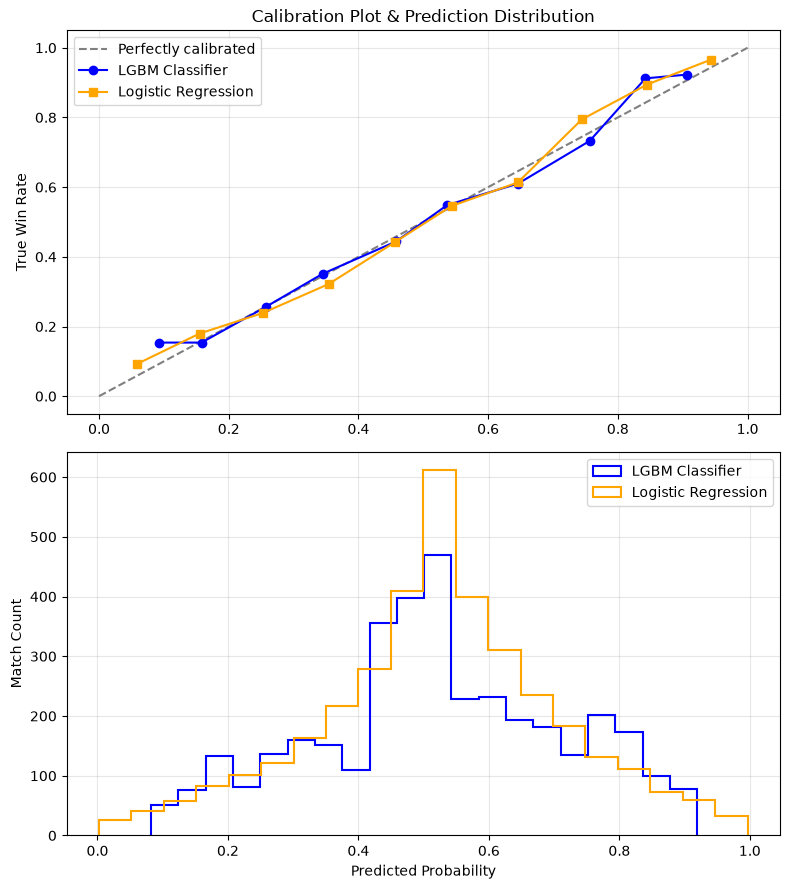

Brier score loss for LGBM Classifier (uncalibrated): 0.21194
Brier score loss for LGBM Classifier (sigmoid calibrated): 0.21168
Brier score loss for LGBM Classifier (isotonic calibrated): 0.21188


,white_winner,white_rating,black_rating,victory_status,turns,increment_code,moves,predicted_probability
11465,0,1450,789,resign,120,10+0,e4 c5 f4 d6 g4 Nf6 g5 Nxe4 d3 Qa5+ c3 Nxg5 fxg...,0.903369
12210,1,1500,2621,outoftime,99,10+5,d4 Nf6 Bg5 g6 e3 Bg7 c4 Ne4 Bf4 c5 Bxb8 Rxb8 N...,0.112292
9860,0,1357,904,resign,47,10+5,d4 e6 e4 Ne7 e5 Nbc6 c4 g6 d5 Nxe5 b3 a6 Bb2 B...,0.886265
12538,1,1762,2220,mate,133,10+0,e4 c5 Nc3 a6 Nf3 b5 a3 Bb7 a4 b4 Na2 Nc6 d4 e6...,0.115822
16611,0,1458,1044,resign,62,10+8,e4 e5 Nf3 Nf6 d3 d6 Bg5 c6 Nc3 Na6 d4 h6 Bh4 g...,0.883771
52,1,978,1500,mate,53,10+0,d4 f5 e3 Nf6 Nc3 d5 Bb5+ c6 Bd3 b5 Qf3 Qa5 Bxf...,0.120420
4273,0,1907,1264,outoftime,70,20+0,d4 Nc6 e3 e5 c4 exd4 exd4 d5 c5 b6 Bb5 Bd7 Qa4...,0.871781
6699,1,1321,1826,mate,83,10+0,Nc3 d5 d4 Nf6 Nf3 Bf5 Bf4 e6 Qd2 Bb4 Bg5 h6 Bx...,0.130657
6250,1,1354,1914,resign,86,25+5,e3 e5 Bd3 Nf6 Nf3 d5 Nxe5 Nc6 Nf3 g6 b3 Bg7 Bb...,0.131379
12154,0,2449,1899,resign,54,20+30,c3 d5 d4 c6 Bd2 f5 Bf4 Nf6 Nf3 Ne4 Nbd2 Nd7 e3...,0.860466


,white_winner,white_rating,black_rating,victory_status,turns,increment_code,moves,predicted_probability
11465,0,1450,789,resign,120,10+0,e4 c5 f4 d6 g4 Nf6 g5 Nxe4 d3 Qa5+ c3 Nxg5 fxg...,0.959332
12538,1,1762,2220,mate,133,10+0,e4 c5 Nc3 a6 Nf3 b5 a3 Bb7 a4 b4 Na2 Nc6 d4 e6...,0.064762
52,1,978,1500,mate,53,10+0,d4 f5 e3 Nf6 Nc3 d5 Bb5+ c6 Bd3 b5 Qf3 Qa5 Bxf...,0.075020
12210,1,1500,2621,outoftime,99,10+5,d4 Nf6 Bg5 g6 e3 Bg7 c4 Ne4 Bf4 c5 Bxb8 Rxb8 N...,0.075826
16611,0,1458,1044,resign,62,10+8,e4 e5 Nf3 Nf6 d3 d6 Bg5 c6 Nc3 Na6 d4 h6 Bh4 g...,0.917632
9860,0,1357,904,resign,47,10+5,d4 e6 e4 Ne7 e5 Nbc6 c4 g6 d5 Nxe5 b3 a6 Bb2 B...,0.894960
6699,1,1321,1826,mate,83,10+0,Nc3 d5 d4 Nf6 Nf3 Bf5 Bf4 e6 Qd2 Bb4 Bg5 h6 Bx...,0.112607
6250,1,1354,1914,resign,86,25+5,e3 e5 Bd3 Nf6 Nf3 d5 Nxe5 Nc6 Nf3 g6 b3 Bg7 Bb...,0.112607
4183,0,1515,1127,mate,26,6+3,d4 e6 c4 Bb4+ Bd2 a5 Nc3 Qf6 e3 Nh6 Bd3 Ng4 Nf...,0.876649
4273,0,1907,1264,outoftime,70,20+0,d4 Nc6 e3 e5 c4 exd4 exd4 d5 c5 b6 Bb5 Bd7 Qa4...,0.876626


Brier score loss for LGBM Classifier : 0.21139
0.9193620936153744
0.7855781999246426


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from lightgbm import LGBMClassifier
from sklearn.metrics import log_loss
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV
from features import ChessDataLoader, FeatureExtractor
from estimator import WinProbEstimator

#week 1 data cleaning and model training
df= pd.read_csv('games.csv')
df.dropna(subset = ['winner', 'white_rating', 'black_rating', 'victory_status', 'opening_eco'], inplace=True)
df.drop_duplicates(subset = ['id'], inplace=True)
df= df[df['winner'] != 'draw'].copy()        
df['white_winner'] = df['winner'].map({'white': 1, 'black': 0})
df['white_winner'] = df['white_winner'].astype(int)
df['elo_diff'] = df['white_rating'] - df['black_rating']

x_lr= df[['elo_diff']]
y_lr = df['white_winner']
x_lr_train, x_lr_test, y_lr_train, y_lr_test = train_test_split(x_lr, y_lr, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(x_lr_train, y_lr_train)
pred_lr_probs = model.predict_proba(x_lr_test)[:, 1]
print(brier_score_loss(y_lr_test, pred_lr_probs))
print(log_loss(y_lr_test, pred_lr_probs))


#week 2 feature engineering
df['avg_rating'] = (df['white_rating'] + df['black_rating']) / 2
df['white_moves'] = df.apply(lambda row: row['moves'].split()[0::2], axis=1)
df['black_moves'] = df.apply(lambda row: row['moves'].split()[1::2], axis=1)
df['white_castled_10'] = df['white_moves'].apply(lambda moves: any(move.startswith('O-O') for move in moves[:10])).astype(int)
df['black_castled_10'] = df['black_moves'].apply(lambda moves: any(move.startswith('O-O') for move in moves[:10])).astype(int)
print(df.groupby('white_castled_10')['white_winner'].mean())
df['white_early_queen_move'] = df['white_moves'].apply(lambda moves: any(move.startswith('Q') for move in moves[:10])).astype(int)
df['black_early_queen_move'] = df['black_moves'].apply(lambda moves: any(move.startswith('Q') for move in moves[:10])).astype(int)
df['eco_group'] = df['opening_eco'].str[0].astype('category')
features = ['elo_diff', 'avg_rating', 'white_castled_10', 'black_castled_10', 'white_early_queen_move', 'black_early_queen_move', 'eco_group']
x_lgb = df[features]
y_lgb = df['white_winner']
x_lgb_train, x_lgb_test, y_lgb_train, y_lgb_test = train_test_split(x_lgb, y_lgb, test_size=0.2, random_state=42)
lgb_model = LGBMClassifier(max_depth= 5, num_leaves = 7, min_child_samples= 100, learning_rate= 0.05, n_estimators=150, random_state=42, verbose=-1)
lgb_model.fit(x_lgb_train, y_lgb_train)
pred_lgb_probs = lgb_model.predict_proba(x_lgb_test)[:, 1]
print(brier_score_loss(y_lgb_test, pred_lgb_probs))
print(log_loss(y_lgb_test, pred_lgb_probs))

#week 3 model evaluation and calibration
prob_true_lgb, prob_pred_lgb = calibration_curve(y_lgb_test, pred_lgb_probs, n_bins=10, strategy='uniform')
prob_true_lr, prob_pred_lr = calibration_curve(y_lr_test, pred_lr_probs, n_bins=10, strategy='uniform')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 9))

ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
ax1.plot(prob_pred_lgb, prob_true_lgb, marker='o', label='LGBM Classifier', color='blue')
ax1.plot(prob_pred_lr, prob_true_lr, marker='s', label='Logistic Regression', color='orange')
ax1.set_ylabel('True Win Rate')
ax1.set_title('Calibration Plot & Prediction Distribution')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.hist(pred_lgb_probs, bins=20, histtype='step', linewidth=1.5, label='LGBM Classifier', color='blue')
ax2.hist(pred_lr_probs, bins=20, histtype='step', linewidth=1.5, label='Logistic Regression', color='orange')
ax2.set_xlabel('Predicted Probability')
ax2.set_ylabel('Match Count')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#sigmoid calibration for LGBM
cal_sigmoid = CalibratedClassifierCV(estimator=lgb_model, method='sigmoid', cv=5)
cal_sigmoid.fit(x_lgb_train, y_lgb_train)
pred_sigmoid_probs = cal_sigmoid.predict_proba(x_lgb_test)[:, 1]

#isotonic calibration for LGBM
cal_isotonic = CalibratedClassifierCV(estimator=lgb_model, method='isotonic', cv=5)
cal_isotonic.fit(x_lgb_train, y_lgb_train)
pred_isotonic_probs = cal_isotonic.predict_proba(x_lgb_test)[:, 1]  

print(f"Brier score loss for LGBM Classifier (uncalibrated): {brier_score_loss(y_lgb_test, pred_lgb_probs):.5f}")
print(f"Brier score loss for LGBM Classifier (sigmoid calibrated): {brier_score_loss(y_lgb_test, pred_sigmoid_probs):.5f}")
print(f"Brier score loss for LGBM Classifier (isotonic calibrated): {brier_score_loss(y_lgb_test, pred_isotonic_probs):.5f}")

abs_error_sigmoid = np.abs(y_lgb_test - pred_sigmoid_probs).sort_values(ascending=False)
abs_error_isotonic = np.abs(y_lgb_test - pred_isotonic_probs).sort_values(ascending=False)
top10_sigmoididx= abs_error_sigmoid.head(10).index
top10_isotonicidx= abs_error_isotonic.head(10).index
s_prob_sigmoid= pd.Series(pred_sigmoid_probs, index=y_lgb_test.index)
s_prob_isotonic= pd.Series(pred_isotonic_probs, index=y_lgb_test.index)
s_prob_sigmoid_top10= df.loc[top10_sigmoididx, ['white_winner', 'white_rating', 'black_rating', 'victory_status', 'turns', 'increment_code', 'moves']].assign(predicted_probability=s_prob_sigmoid[top10_sigmoididx].values)
s_prob_isotonic_top10= df.loc[top10_isotonicidx, ['white_winner', 'white_rating', 'black_rating', 'victory_status', 'turns', 'increment_code', 'moves']].assign(predicted_probability=s_prob_isotonic[top10_isotonicidx].values)
display(s_prob_sigmoid_top10, s_prob_isotonic_top10)

#week 4 model deployment oop
loader= ChessDataLoader('games.csv')
df= loader.load_and_clean()

extractor = FeatureExtractor()
X = extractor.transform(df)
y = df['white_win']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42)
estimator= WinProbEstimator()
estimator.fit(X_train, y_train)
estimator.evaluate(X_test, y_test)

print(estimator.predict_match(white_elo=2000, black_elo=1000, opening_moves ="e4 e5 Nf3 Nc6 Bc4 Bc5 O-O Nf6", opening_eco='B01'))
print(estimator.predict_match(white_elo=1800, black_elo=1500, opening_moves="e4 e5 Qh5 Nc6 Bc4 g6 Qf3", opening_eco='C20'))
